# Rent 02 · Explore HPD violations
**Dataset:** [Housing Maintenance Code Violations](https://data.cityofnewyork.us/d/wvxf-dwi5), downloaded by inspection date from Jan 2022 → today, in `data/raw/hpd_violations/`.

**Complaint vs violation:**
- A **complaint** is what a tenant says.
- A **violation** is what an HPD **inspector confirmed** and legally ordered the landlord to fix. It's stronger evidence.

Violations are rated by severity:

| Class | Meaning | Correction deadline |
|---|---|---|
| A | Non-hazardous | 90 days |
| B | Hazardous | 30 days |
| C | Immediately hazardous (no heat, lead paint, rodents, broken locks …) | 24 hours |
| I | Information order | – |

**Questions for this notebook:**
1. How many violations are there, and how severe?
2. What are they about? The text is free-form, so we categorize it with regex.
3. How long do they stay open?
4. Do violations and complaints point at the same buildings?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = pd.read_parquet(config.CLEAN_PLUTO_FILE, columns=["bbl", "is_residential", "unitsres", "yearbuilt"])
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## 1. Size and severity

In [2]:
rows = H.monthly_rows("hpd_violations")
print(f"{rows.sum():,} violations | {rows.index[0]} → {rows.index[-1]}")
cols = ["violationid", "bbl", "apartment", "class", "inspectiondate", "novissueddate", "ordernumber",
        "novdescription", "currentstatus", "violationstatus", "rentimpairing"]
v = H.load("hpd_violations", cols)
v["inspectiondate"] = pd.to_datetime(v["inspectiondate"].astype(str), errors="coerce")
v["year"] = v["inspectiondate"].dt.year
H.overview(v)

4,492,764 violations | 2022-01 → 2026-11


,missing_%,distinct,example
violationid,0.00,4492764,14753192
bbl,0.10,176592,3060860065
apartment,38.40,9832,5C
class,0.00,4,C
inspectiondate,0.00,1788,2022-01-01 00:00:00
novissueddate,8.90,1216,2022-01-03T00:00:00.000
ordernumber,0.00,358,670
novdescription,0.00,2471228,§ 27-2031 ADM CODE PROVIDE HOT WATER AT ALL HOT WATER FIXTURES IN THE ENTIRE...
currentstatus,0.00,21,VIOLATION CLOSED
violationstatus,0.00,2,Close


Duplicate violation ids: 0


class,A,B,C,I
year,,,,
2022,229958,279375,202754,147328
2023,226431,327929,249757,76673
2024,235543,396541,297778,65566
2025,206976,364224,278207,68566
2026,210167,347731,242086,39174


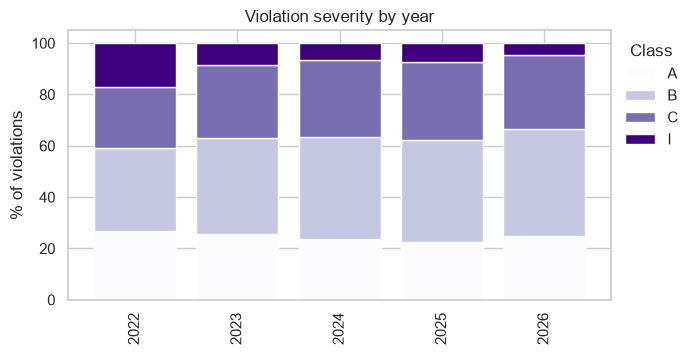

In [3]:
print(f"Duplicate violation ids: {v['violationid'].duplicated().sum():,}")
sev = pd.crosstab(v["year"], v["class"])
display(sev)
ax = sev.div(sev.sum(axis=1), axis=0).mul(100).plot(kind="bar", stacked=True, figsize=(7, 3.5),
                                                       colormap="Purples", width=0.8)
ax.set(ylabel="% of violations", xlabel="", title="Violation severity by year")
ax.legend(title="Class", bbox_to_anchor=(1, 1), frameon=False)
save(ax.figure, "rent02a_violation_class")

## 2. What are violations about? (regex topic tagging)

In [4]:
print("Example descriptions:")
for t in v["novdescription"].dropna().sample(5, random_state=3):
    print(" -", str(t)[:160])
v["topic"] = H.violation_topic(v["novdescription"])
topics = v["topic"].value_counts(normalize=True).mul(100).round(1)
print(f"\nTagged (not 'other'): {100 - topics.get('other', 0):.1f}%")
pd.crosstab(v["topic"], v["class"], margins=True).sort_values("All", ascending=False)

Example descriptions:


 - HMC ADM CODE: § 27-2017.4 ABATE THE INFESTATION CONSISTING OF ROACHES IN THE ENTIRE APARTMENT LOCATED AT APT B1, 2nd STORY
 - (A) § HMC:FILE ANNUAL BEDBUG REPORT IN ACCORDANCE WITH HPD RULE AS DESCRIBED ON THE BACK OF THIS NOTICE OF VIOLATION OR AS DESCRIBED ON HPDS WEBSITE, WWW.NYC.G
 - § 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE CERAMIC FLOOR TILES IN THE BATHROOM LOCATED AT APT 56, 5th STORY, 1st APARTMENT
 - § 27-2026, 2027 HMC: PROPERLY REPAIR THE SOURCE AND ABATE THE EVIDENCE OF A WATER LEAK AT CEILING IN THE 2nd ROOM FROM EAST LOCATED AT APT 3E, 3rd STORY, 3rd AP
 - §27-2107 ADM CODE OWNER FAILED TO FILE A VALID REGISTRATION STATEMENT WITH THE DEPARTMENT AS REQUIRED BY ADM CODE §27-2097 AND IS THEREFORE SUBJECT TO CIVIL PEN



Tagged (not 'other'): 92.1%


class,A,B,C,I,All
topic,,,,,
All,1109075,1715798,1270578,397307,4492758
pests,419477,32026,306377,0,757880
paint/plaster,300333,305183,37853,0,643369
mold/leaks,128676,313959,47651,0,490286
fire safety,42679,365491,57103,25,465298
doors/locks,36158,120207,301855,272,458492
admin (registration/signs),57487,4053,160,390883,452583
other,57432,228137,64787,6124,356480
heat/hot water,4540,11048,213817,1,229406


In [5]:
# What's left in 'other'? Shows which regex patterns still need adding.
v.loc[v["topic"] == "other", "novdescription"].astype(str).str[:90].value_counts().head(12).to_frame("count")

,count
novdescription,
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE WOOD FLOO,43902
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE VINYL FLO,17508
"§ 27-2010, 2011, 2012 ADM CODE REMOVE THE ACCUMULATION OF REFUSE AND/OR RUBBISH AND MAINTA",17013
"§ 329, M/D LAW AND DEPT. RULES AND REGS. PROVIDE A COMPLETED CERTIFICATE OF INSPECTION VIS",16319
§ 27-2070 ADM CODE PROVIDE AN ADEQUATE SUPPLY OF GAS TO THE FIXTURES AT RANGE IN THE KITCH,10228
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE CERAMIC F,8846
"§ 27-2005, 2007 ADM CODE REMOVE ALL ENCUMBRANCES CONSISTING OF HOUSEHOLD ITEMS AT PUBLIC H",7449
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE VINYL TIL,6568
"§ 27-2021 ADM CODE PROVIDE SUFFICIENT, PROPER AND SEPARATE METAL RECEPTACLES FOR THE DEPOS",5156


In [6]:
# Order numbers are a cleaner code for the violation type than the free text
v["ordernumber"].value_counts().head(15).to_frame("violations").join(
    v.groupby("ordernumber")["topic"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None).rename("main topic"))

,violations,main topic
ordernumber,,
1507,419146,pests
780,388744,admin (registration/signs)
508,357512,paint/plaster
501,322375,doors/locks
502,289206,other
530,279626,doors/locks
556,204894,paint/plaster
550,183929,mold/leaks
568,163877,pests


## 3. How long do violations stay open?

In [7]:
display(v["violationstatus"].value_counts(normalize=True).mul(100).round(1).to_frame("%").T)
open_share = v.groupby(["year", "class"])["violationstatus"].apply(lambda s: (s == "Open").mean()).unstack()
open_share.mul(100).round(1)

violationstatus,Close,Open
%,66.00,34.00


class,A,B,C,I
year,,,,
2022,21.70,22.80,18.00,29.00
2023,24.70,24.90,20.10,34.80
2024,27.90,28.00,22.50,47.60
2025,36.90,36.90,28.50,57.20
2026,61.70,63.70,52.60,96.80


In [8]:
print(f"Rent-impairing violations: {(v['rentimpairing'] == 'Y').mean():.1%}  "
      "(serious enough that tenants can legally withhold rent)")
v["currentstatus"].value_counts().head(10).to_frame("violations")

Rent-impairing violations: 6.7%  (serious enough that tenants can legally withhold rent)


,violations
currentstatus,
VIOLATION DISMISSED,1547297
VIOLATION CLOSED,1387877
NOV SENT OUT,853380
INFO NOV SENT OUT,176659
FIRST NO ACCESS TO RE- INSPECT VIOLATION,126563
NOT COMPLIED WITH,116173
NOTICE OF ISSUANCE SENT TO TENANT,68190
VIOLATION WILL BE REINSPECTED,50711
CIV14 MAILED,38759


## 4. Buildings: concentration and overlap with complaints

In [9]:
per_bldg = v.dropna(subset=["bbl"]).groupby("bbl").size()
print(f"Buildings with violations: {len(per_bldg):,}; BBLs matching PLUTO: {H.coverage(v['bbl'], pluto_bbls):.1%}")
display(H.concentration(per_bldg).map("{:.0%}".format).to_frame("share of all violations").T)
complaint_bbls = set(H.load("hpd_complaints", ["bbl"])["bbl"].dropna())
viol_bbls = set(per_bldg.index)
print(f"Buildings with complaints: {len(complaint_bbls):,} | with violations: {len(viol_bbls):,} | "
      f"both: {len(complaint_bbls & viol_bbls):,}")
print(f"Share of complaint buildings that also got a violation: {len(complaint_bbls & viol_bbls) / len(complaint_bbls):.1%}")

Buildings with violations: 176,592; BBLs matching PLUTO: 99.8%


,top 1%,top 5%,top 10%
share of all violations,27%,56%,70%


Buildings with complaints: 123,070 | with violations: 176,592 | both: 89,390
Share of complaint buildings that also got a violation: 72.6%


## 5. Takeaways
- **Class C** (immediately hazardous) is the key severity signal for a renter. Count it separately.
- The regex topics map violations onto the **same problem types** as complaints (heat, pests, mold/leaks, …). Patterns to add are listed in the "other" table above.
- Keep `violationstatus` and `rentimpairing`: an **open** class C violation is a red flag at signing time.
- Complaints and violations overlap but are not identical. Some buildings complain without being cited, and that gap is itself informative.

→ Next: **rent_03_explore_landlords.ipynb**